# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
# Task 3 - GRPO Workbench

## Shared Setup

In [1]:
import os
import sys
from pathlib import Path

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in candidates if (path / 'configs' / 'grpo.yaml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from common.data import load_yaml, read_jsonl, repo_path
from task3_grpo.core.protocol import validate_shared_protocol

CONFIG_PATH = 'configs/grpo.yaml'
OVERWRITE = False
config = load_yaml(CONFIG_PATH)
validate_shared_protocol(config)
pd.set_option('display.max_colwidth', 240)
print('Project root:', PROJECT_ROOT)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Project root: c:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


### Model download/cache safety block

In [3]:
from huggingface_hub import snapshot_download

for model_id in [config['base_model'], config['reward_model']]:
    cached_path = snapshot_download(repo_id=model_id)
    print(f'{model_id} -> {cached_path}')

midpoint = repo_path(config['paths']['grpo_midpoint_policy'])
if not midpoint.exists():
    raise FileNotFoundError(f'Missing released GRPO midpoint: {midpoint}')
print('Released midpoint:', midpoint)

c:\Users\DanishZaheer\anaconda3\envs\ATML\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 1666.66it/s]


Qwen/Qwen2.5-1.5B-Instruct -> C:\Users\DanishZaheer\.cache\huggingface\hub\models--Qwen--Qwen2.5-1.5B-Instruct\snapshots\989aa7980e4cf806f80c7fef2b1adb7bc71aa306


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 2322.61it/s]

yavuz-ai/qwen2.5-1.5b-rm-ultrafeedback -> C:\Users\DanishZaheer\.cache\huggingface\hub\models--yavuz-ai--qwen2.5-1.5b-rm-ultrafeedback\snapshots\f98759a4a1ccdc47a3136748b6bfea9a32ba8fcc
Released midpoint: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\checkpoints\grpo_midpoint_policy


### Fast validation before any training

In [4]:
import subprocess
subprocess.run([
    sys.executable, '-m', 'unittest', 'discover',
    '-s', 'task3_grpo/tests', '-v'
], check=True)

CompletedProcess(args=['c:\\Users\\DanishZaheer\\anaconda3\\envs\\ATML\\python.exe', '-m', 'unittest', 'discover', '-s', 'task3_grpo/tests', '-v'], returncode=0)

## Task 3 - Part 1

In [5]:
from task3_grpo.core.trainer import train_grpo_continuation

standard_training = train_grpo_continuation(
    config_path=CONFIG_PATH,
    run_name='standard',
    updates=config['updates'],
    loss_type='grpo',
    overwrite=OVERWRITE,
)
standard_training

Using completed standard GRPO continuation.


{'run_name': 'standard',
 'loss_type': 'grpo',
 'updates': 20,
 'prompts_per_update': 1,
 'num_generations': 4,
 'seed': 6304,
 'generated_tokens': 24807,
 'maximum_generation_budget': 40960,
 'training_reward_device': 'cpu',
 'wall_time_seconds': 2350.2415498999762,
 'peak_vram_gib': 3.847472667694092,
 'policy_directory': 'C:\\Users\\DanishZaheer\\Desktop\\LUMS\\Semester_3\\ATML\\PA_2\\task3_grpo\\outputs\\standard\\policy',
 'policy_sha256': 'b9d63bb4e26fe0cd1735e9887b213c8e26176ac324b92638c67c378d7e590211'}

### Part 1 held-out evaluation

In [6]:
from task3_grpo.evaluate import run_evaluation

standard_evaluation = run_evaluation(
    config_path=CONFIG_PATH, name='standard', overwrite=OVERWRITE
)
display(pd.DataFrame([standard_evaluation]).drop(columns=['evaluation_protocol', 'reward_scoring_protocol']))

Using completed standard held-out evaluation.


,run_name,adapter_sha256,evaluation_prompts,response_tokens,reward_model_score_mean,reward_model_score_std,sampled_kl_token_mean,entropy_token_mean,response_length_mean,response_length_std,response_length_iqr,terminated_fraction,truncated_fraction
0,standard,b9d63bb4e26fe0cd1735e9887b213c8e26176ac324b92638c67c378d7e590211,200,49788,1.51496,1.225793,0.000111,1.013495,248.94,190.17328,398.5,0.78,0.22


,run_name,updates,num_generations,training_generated_tokens,wall_time_seconds,peak_vram_gib,final_train_reward,final_train_sampled_kl,mean_within_group_reward_std,mean_uninformative_group_fraction,...,final_gradient_norm,final_entropy,final_response_length,heldout_reward,heldout_reward_std,heldout_sampled_kl,heldout_entropy,heldout_response_length,heldout_response_length_std,heldout_truncated_fraction
0,standard,20,4,24807,2350.24155,3.847473,0.406677,0.000147,0.538222,0.05,...,0.569284,0.704888,89.0,1.51496,1.225793,0.000111,1.013495,248.94,190.17328,0.22


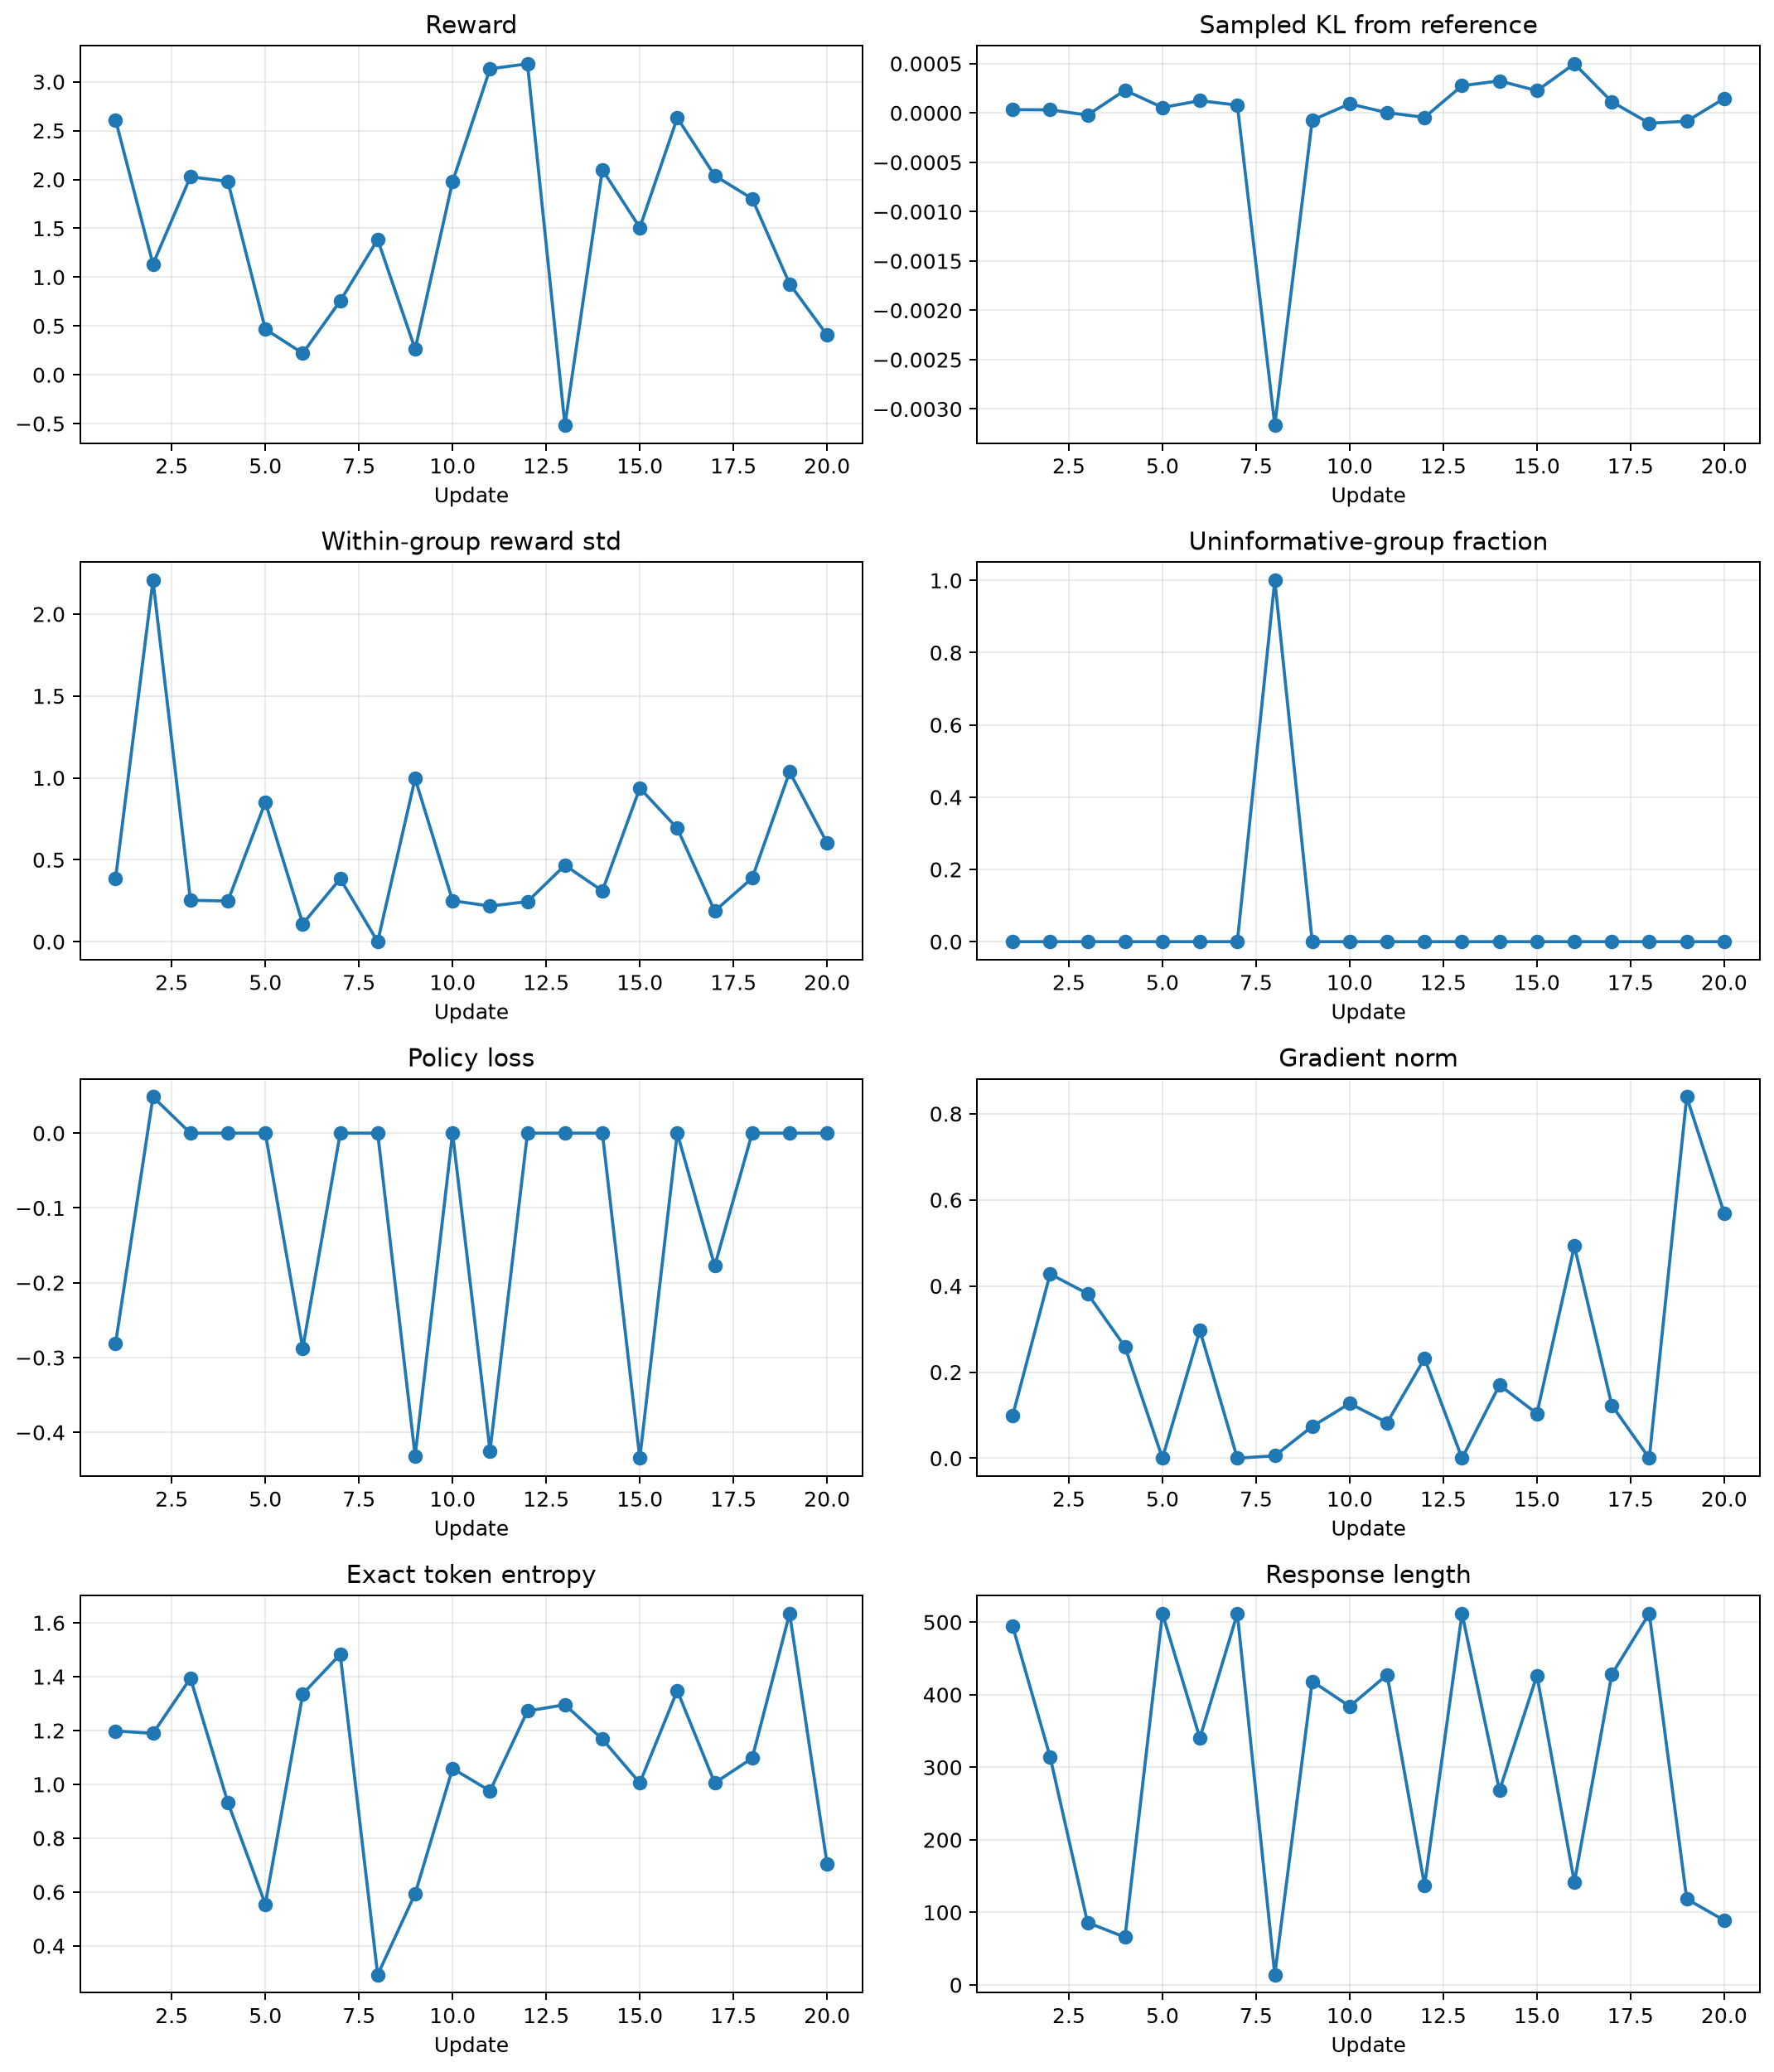

In [7]:
standard_dir = repo_path(config['results_dir']) / 'standard'
display(pd.read_csv(standard_dir / 'summary.csv'))
display(Image(filename=str(repo_path(config['results_dir']) / 'figures' / 'standard_training.png')))

## Task 3 - Part 2

In [8]:
from task3_grpo.analyze_group_size import run_group_size_study

group_size_result = run_group_size_study(CONFIG_PATH)
group_dir = repo_path(config['results_dir']) / 'group_size'
display(pd.read_csv(group_dir / 'summary.csv'))
display(pd.read_csv(group_dir / 'difficulty_summary.csv'))

,k,difficulty,prompt_count,group_count,completion_count,informative_group_rate,uninformative_group_rate,mean_within_group_reward_std,variance_group_relative_signal
0,2,all,24,96,192,0.937500,0.062500,0.384567,0.937500
1,4,all,24,48,192,0.958333,0.041667,0.541004,0.958333
2,8,all,24,24,192,0.958333,0.041667,0.619054,0.958333


,k,difficulty,prompt_count,group_count,completion_count,informative_group_rate,uninformative_group_rate,mean_within_group_reward_std,variance_group_relative_signal
0,2,hard,8,32,64,0.84375,0.15625,0.493401,0.84375
1,2,medium,8,32,64,0.96875,0.03125,0.412376,0.96875
2,2,easy,8,32,64,1.00000,0.00000,0.247925,1.00000
3,4,hard,8,16,64,0.87500,0.12500,0.661488,0.87500
4,4,medium,8,16,64,1.00000,0.00000,0.551694,1.00000
5,4,easy,8,16,64,1.00000,0.00000,0.409831,1.00000
6,8,hard,8,8,64,0.87500,0.12500,0.763369,0.87500
7,8,medium,8,8,64,1.00000,0.00000,0.599022,1.00000
8,8,easy,8,8,64,1.00000,0.00000,0.494772,1.00000


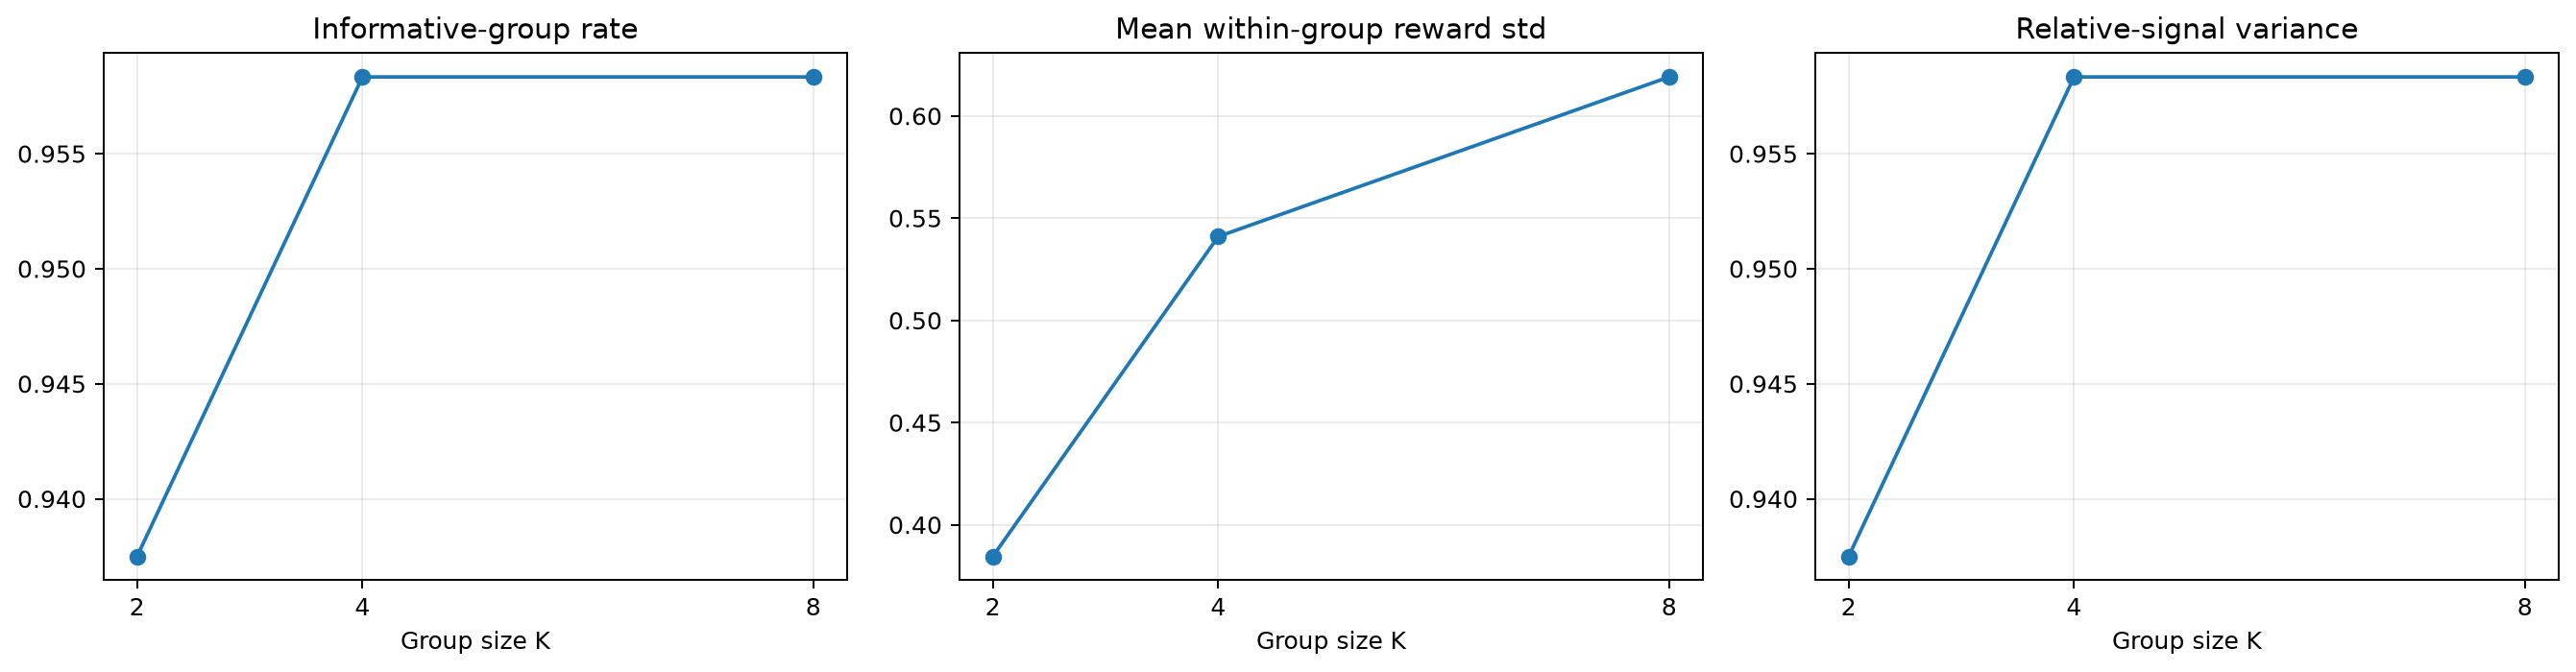

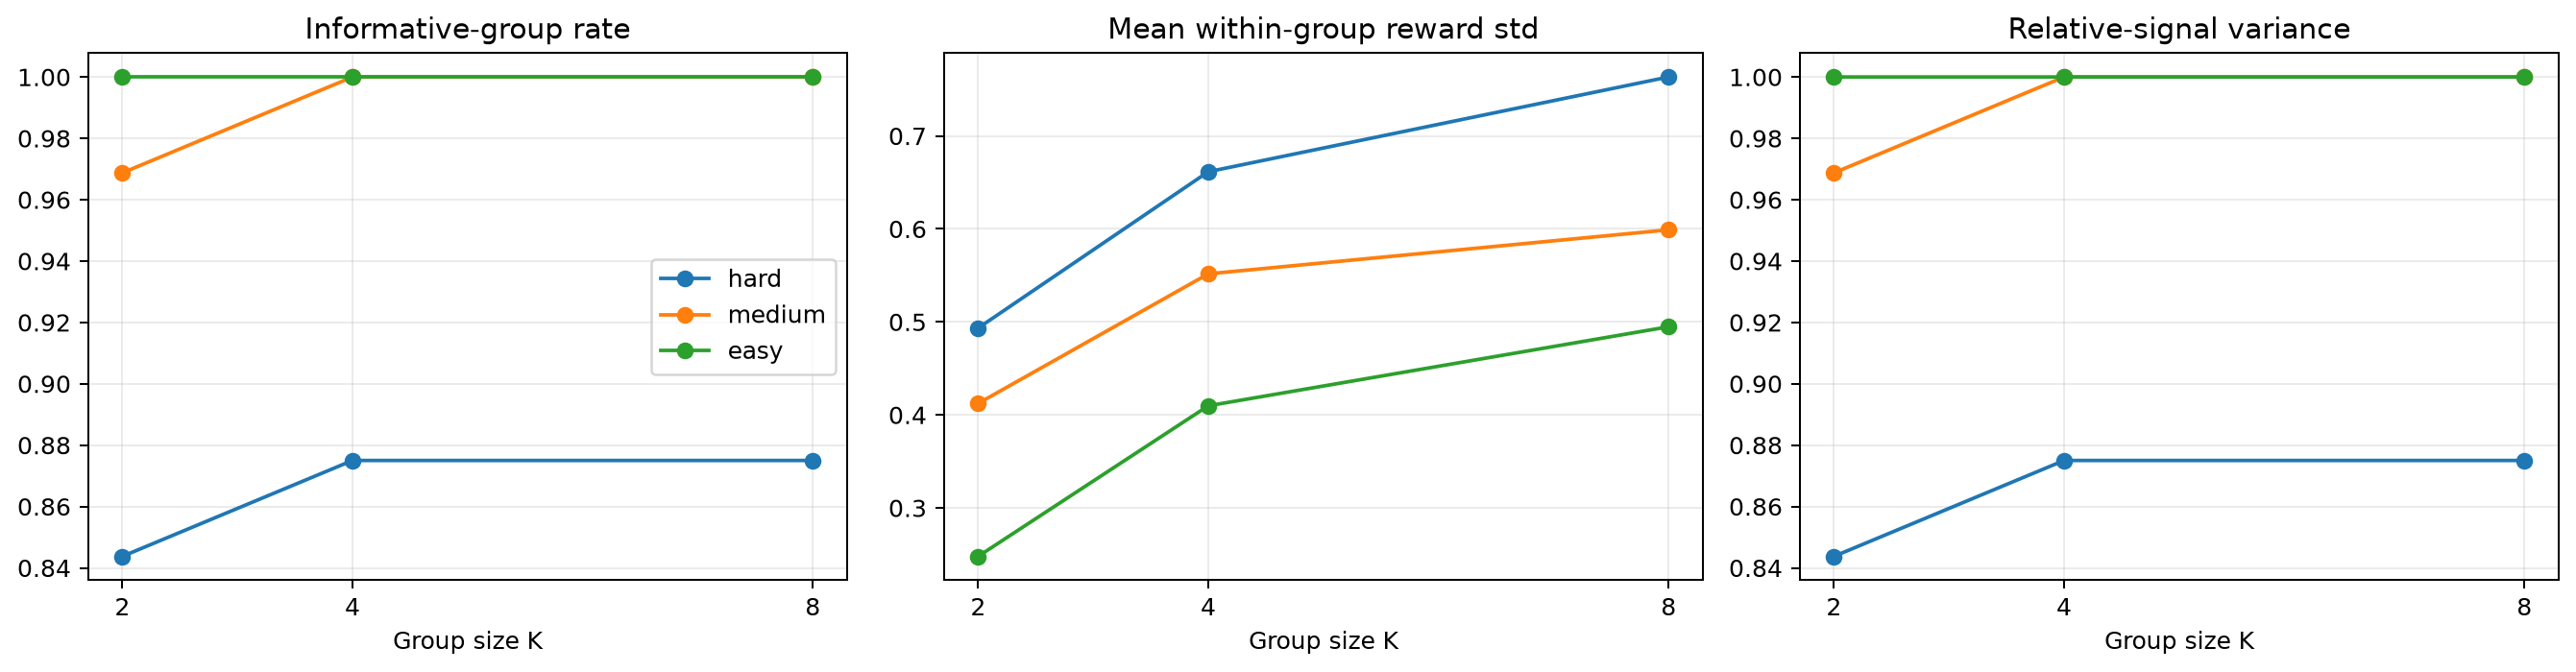

,reason,difficulty,informative,reward_std,prompt_id
0,largest_reward_spread,hard,True,1.979574,01a4b2ed4479c8fa682c3466f7db16f277168d90c8450a729089f4527345ee8d
1,uninformative_equal_reward_group,hard,False,0.000000,be78486affffe4f57015a153c5529c949aeb7511e1f30ed76da522452f245bed
2,largest_reward_spread,medium,True,1.077411,cb3bebe583bd8475019b58042be3a76432b23c81b79b32c441d4b3bf203760df
3,largest_reward_spread,easy,True,1.220473,bdfcf969f2a84458b2498e0acc198d3094334b81d595fed1724210d7c9f89279


In [9]:
figures_dir = repo_path(config['results_dir']) / 'figures'
display(Image(filename=str(figures_dir / 'group_size_overall.png')))
display(Image(filename=str(figures_dir / 'group_size_by_difficulty.png')))
group_examples = read_jsonl(group_dir / 'qualitative_examples.jsonl')
display(pd.DataFrame([{
    'reason': row['selection_reason'],
    'difficulty': row['difficulty'],
    'informative': row['informative'],
    'reward_std': row['within_group_reward_std'],
    'prompt_id': row['prompt_id'],
} for row in group_examples]))

## Task 3 - Part 3

In [10]:
from task3_grpo.compare_normalization import run_normalization_study

normalization_result = run_normalization_study(
    config_path=CONFIG_PATH, overwrite=OVERWRITE
)
normalization_root = repo_path(config['results_dir']) / 'normalization'
display(pd.read_csv(normalization_root / 'summary.csv'))
display(pd.read_csv(normalization_root / 'length_conditioned_metrics.csv'))

Using completed norm_canonical GRPO continuation.
Using completed norm_canonical held-out evaluation.
Using completed norm_dr_grpo GRPO continuation.
Using completed norm_dr_grpo held-out evaluation.


,run_name,loss_type,updates,maximum_generation_budget,actual_generated_tokens,wall_time_seconds,peak_vram_gib,mean_train_reward,mean_train_kl,mean_gradient_norm,gradient_norm_std,gradient_weight_length_correlation,heldout_reward,heldout_reward_std,heldout_sampled_kl,heldout_entropy,heldout_response_length,heldout_response_length_std,heldout_truncated_fraction
0,norm_canonical,grpo,8,16384,9356,867.813331,3.847419,1.322237,-0.000329,0.183802,0.167269,0.195898,1.502654,1.214881,0.000093,0.998901,248.475,189.536406,0.220
1,norm_dr_grpo,dr_grpo,8,16384,9514,853.760974,3.847419,1.503833,-0.000559,0.046332,0.038957,0.833489,1.548684,1.212263,0.000155,1.005802,248.990,188.718626,0.215


,run_name,loss_type,length_bin,lower_exclusive,upper_inclusive,completion_count,trainable_completion_count,mean_response_length,mean_reward,mean_absolute_advantage,mean_per_token_gradient_weight,mean_sequence_gradient_weight_proxy,truncated_fraction
0,norm_canonical,grpo,short,0,170,14,14,58.500000,1.383946,0.741579,0.011049,0.741579,0.0000
1,norm_canonical,grpo,medium,170,341,2,2,244.000000,1.451721,0.594641,0.002408,0.594641,0.0000
2,norm_canonical,grpo,long,341,512,16,3,503.062500,1.252056,0.850078,0.001802,0.850078,0.8125
3,norm_dr_grpo,dr_grpo,short,0,170,13,13,56.230769,1.696608,0.677651,0.001324,0.108556,0.0000
4,norm_dr_grpo,dr_grpo,medium,170,341,3,3,244.666667,1.635132,0.620084,0.001211,0.301955,0.0000
5,norm_dr_grpo,dr_grpo,long,341,512,16,3,503.062500,1.322584,0.940972,0.001838,0.863365,0.8125


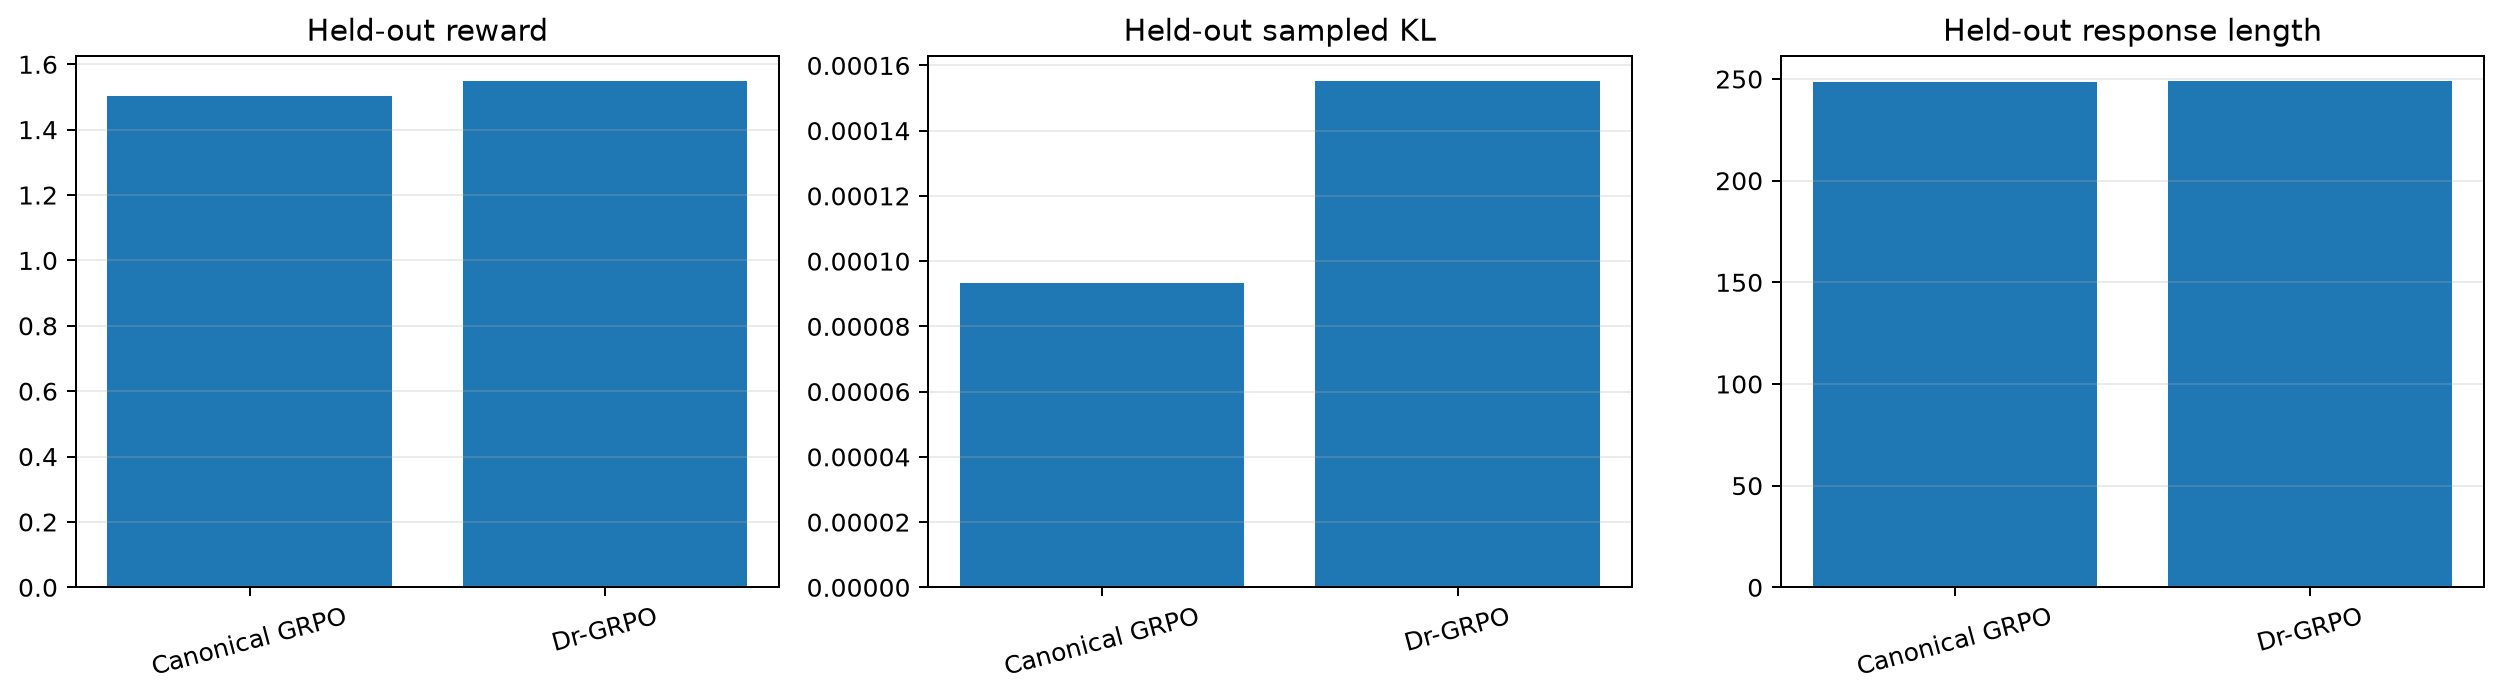

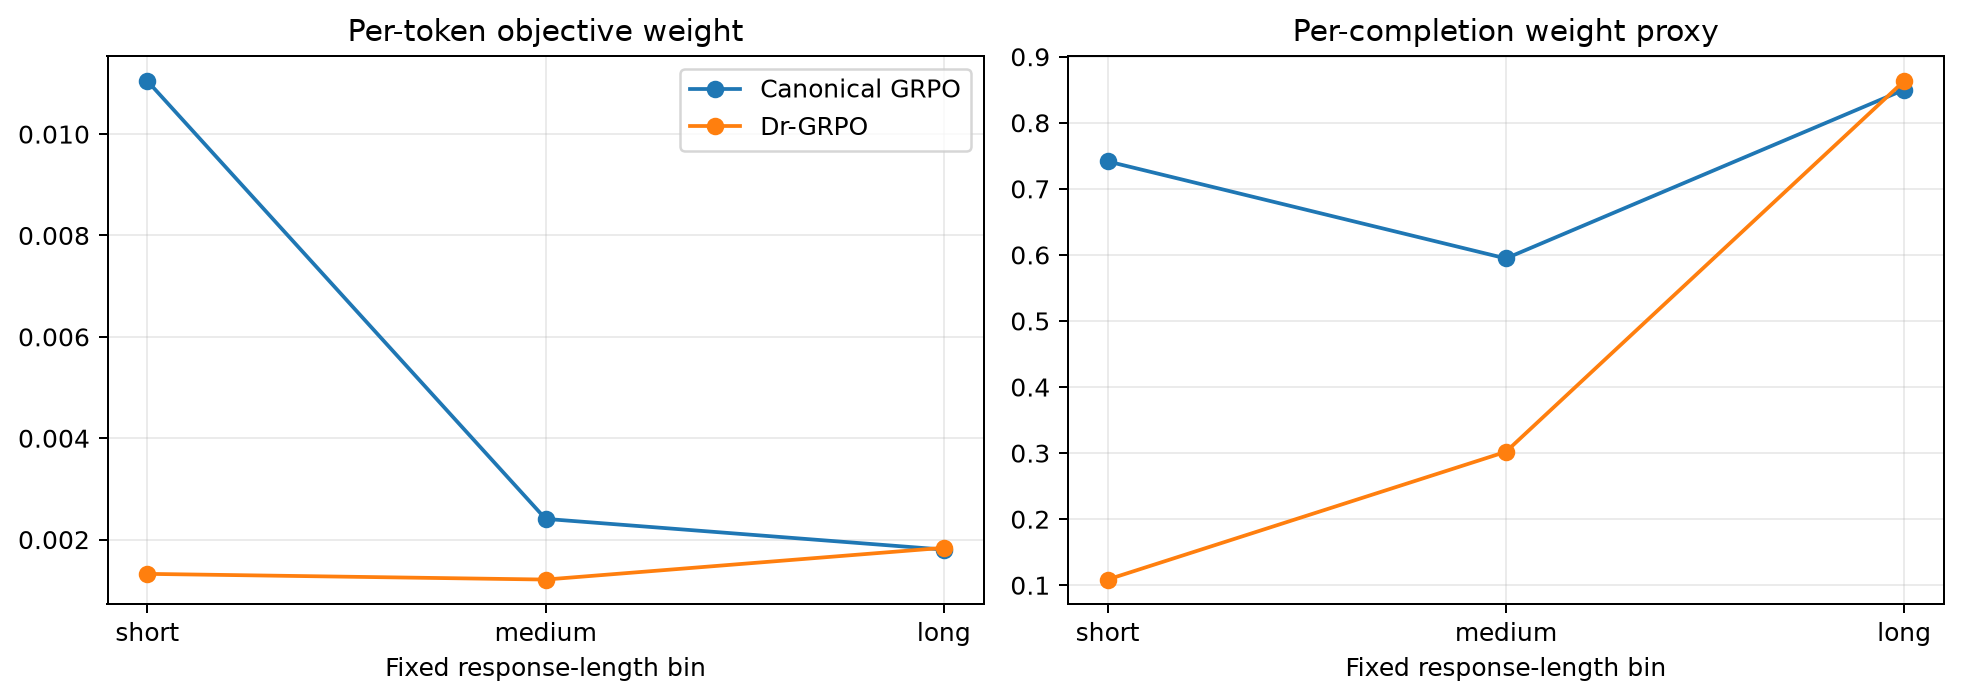

,prompt_id,source_index,reward_dr_minus_canonical,kl_dr_minus_canonical,length_dr_minus_canonical
count,200,200.000000,200.000000,200.000000,200.000000
unique,200,NaN,NaN,NaN,NaN
top,d407599fef051a44d505c8439c3c6a6fb7d8fb6658384a4c391e9c2f2146f16d,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN
mean,NaN,503.210000,0.046030,-0.000029,0.515000
std,NaN,286.593519,0.448435,0.000839,27.625816
min,NaN,2.000000,-3.317383,-0.005054,-99.000000
25%,NaN,238.250000,0.000000,-0.000302,0.000000
50%,NaN,505.000000,0.000000,0.000020,0.000000
75%,NaN,766.250000,0.000000,0.000262,0.000000


In [11]:
figures_dir = repo_path(config['results_dir']) / 'figures'
display(Image(filename=str(figures_dir / 'normalization_heldout.png')))
display(Image(filename=str(figures_dir / 'normalization_length_allocation.png')))
paired = pd.read_csv(normalization_root / 'paired_heldout_differences.csv')
display(paired.describe(include='all'))

## More for research questions

,updates,generated_tokens,mean_uninformative_group_fraction,mean_truncated_completion_fraction,informative_groups_across_updates,generated_tokens_per_informative_group,within_group_reward_std_cv,gradient_norm_cv,policy_loss_standard_deviation,reward_standard_deviation_across_updates,note
0,20,24807,0.05,0.325,19.0,1305.631579,0.899289,1.035988,0.166349,1.000403,These are candidate mechanisms for RQ3. The student should identify the dominant one only after comparing the numerical evidence and examples.


,k,difficulty,prompt_count,group_count,completion_count,informative_group_rate,uninformative_group_rate,mean_within_group_reward_std,variance_group_relative_signal
0,2,all,24,96,192,0.937500,0.062500,0.384567,0.937500
1,4,all,24,48,192,0.958333,0.041667,0.541004,0.958333
2,8,all,24,24,192,0.958333,0.041667,0.619054,0.958333


,k,difficulty,prompt_count,group_count,completion_count,informative_group_rate,uninformative_group_rate,mean_within_group_reward_std,variance_group_relative_signal
0,2,hard,8,32,64,0.84375,0.15625,0.493401,0.84375
1,2,medium,8,32,64,0.96875,0.03125,0.412376,0.96875
2,2,easy,8,32,64,1.00000,0.00000,0.247925,1.00000
3,4,hard,8,16,64,0.87500,0.12500,0.661488,0.87500
4,4,medium,8,16,64,1.00000,0.00000,0.551694,1.00000
5,4,easy,8,16,64,1.00000,0.00000,0.409831,1.00000
6,8,hard,8,8,64,0.87500,0.12500,0.763369,0.87500
7,8,medium,8,8,64,1.00000,0.00000,0.599022,1.00000
8,8,easy,8,8,64,1.00000,0.00000,0.494772,1.00000


,run_name,loss_type,updates,maximum_generation_budget,actual_generated_tokens,wall_time_seconds,peak_vram_gib,mean_train_reward,mean_train_kl,mean_gradient_norm,gradient_norm_std,gradient_weight_length_correlation,heldout_reward,heldout_reward_std,heldout_sampled_kl,heldout_entropy,heldout_response_length,heldout_response_length_std,heldout_truncated_fraction
0,norm_canonical,grpo,8,16384,9356,867.813331,3.847419,1.322237,-0.000329,0.183802,0.167269,0.195898,1.502654,1.214881,0.000093,0.998901,248.475,189.536406,0.220
1,norm_dr_grpo,dr_grpo,8,16384,9514,853.760974,3.847419,1.503833,-0.000559,0.046332,0.038957,0.833489,1.548684,1.212263,0.000155,1.005802,248.990,188.718626,0.215


,run_name,loss_type,length_bin,lower_exclusive,upper_inclusive,completion_count,trainable_completion_count,mean_response_length,mean_reward,mean_absolute_advantage,mean_per_token_gradient_weight,mean_sequence_gradient_weight_proxy,truncated_fraction
0,norm_canonical,grpo,short,0,170,14,14,58.500000,1.383946,0.741579,0.011049,0.741579,0.0000
1,norm_canonical,grpo,medium,170,341,2,2,244.000000,1.451721,0.594641,0.002408,0.594641,0.0000
2,norm_canonical,grpo,long,341,512,16,3,503.062500,1.252056,0.850078,0.001802,0.850078,0.8125
3,norm_dr_grpo,dr_grpo,short,0,170,13,13,56.230769,1.696608,0.677651,0.001324,0.108556,0.0000
4,norm_dr_grpo,dr_grpo,medium,170,341,3,3,244.666667,1.635132,0.620084,0.001211,0.301955,0.0000
5,norm_dr_grpo,dr_grpo,long,341,512,16,3,503.062500,1.322584,0.940972,0.001838,0.863365,0.8125


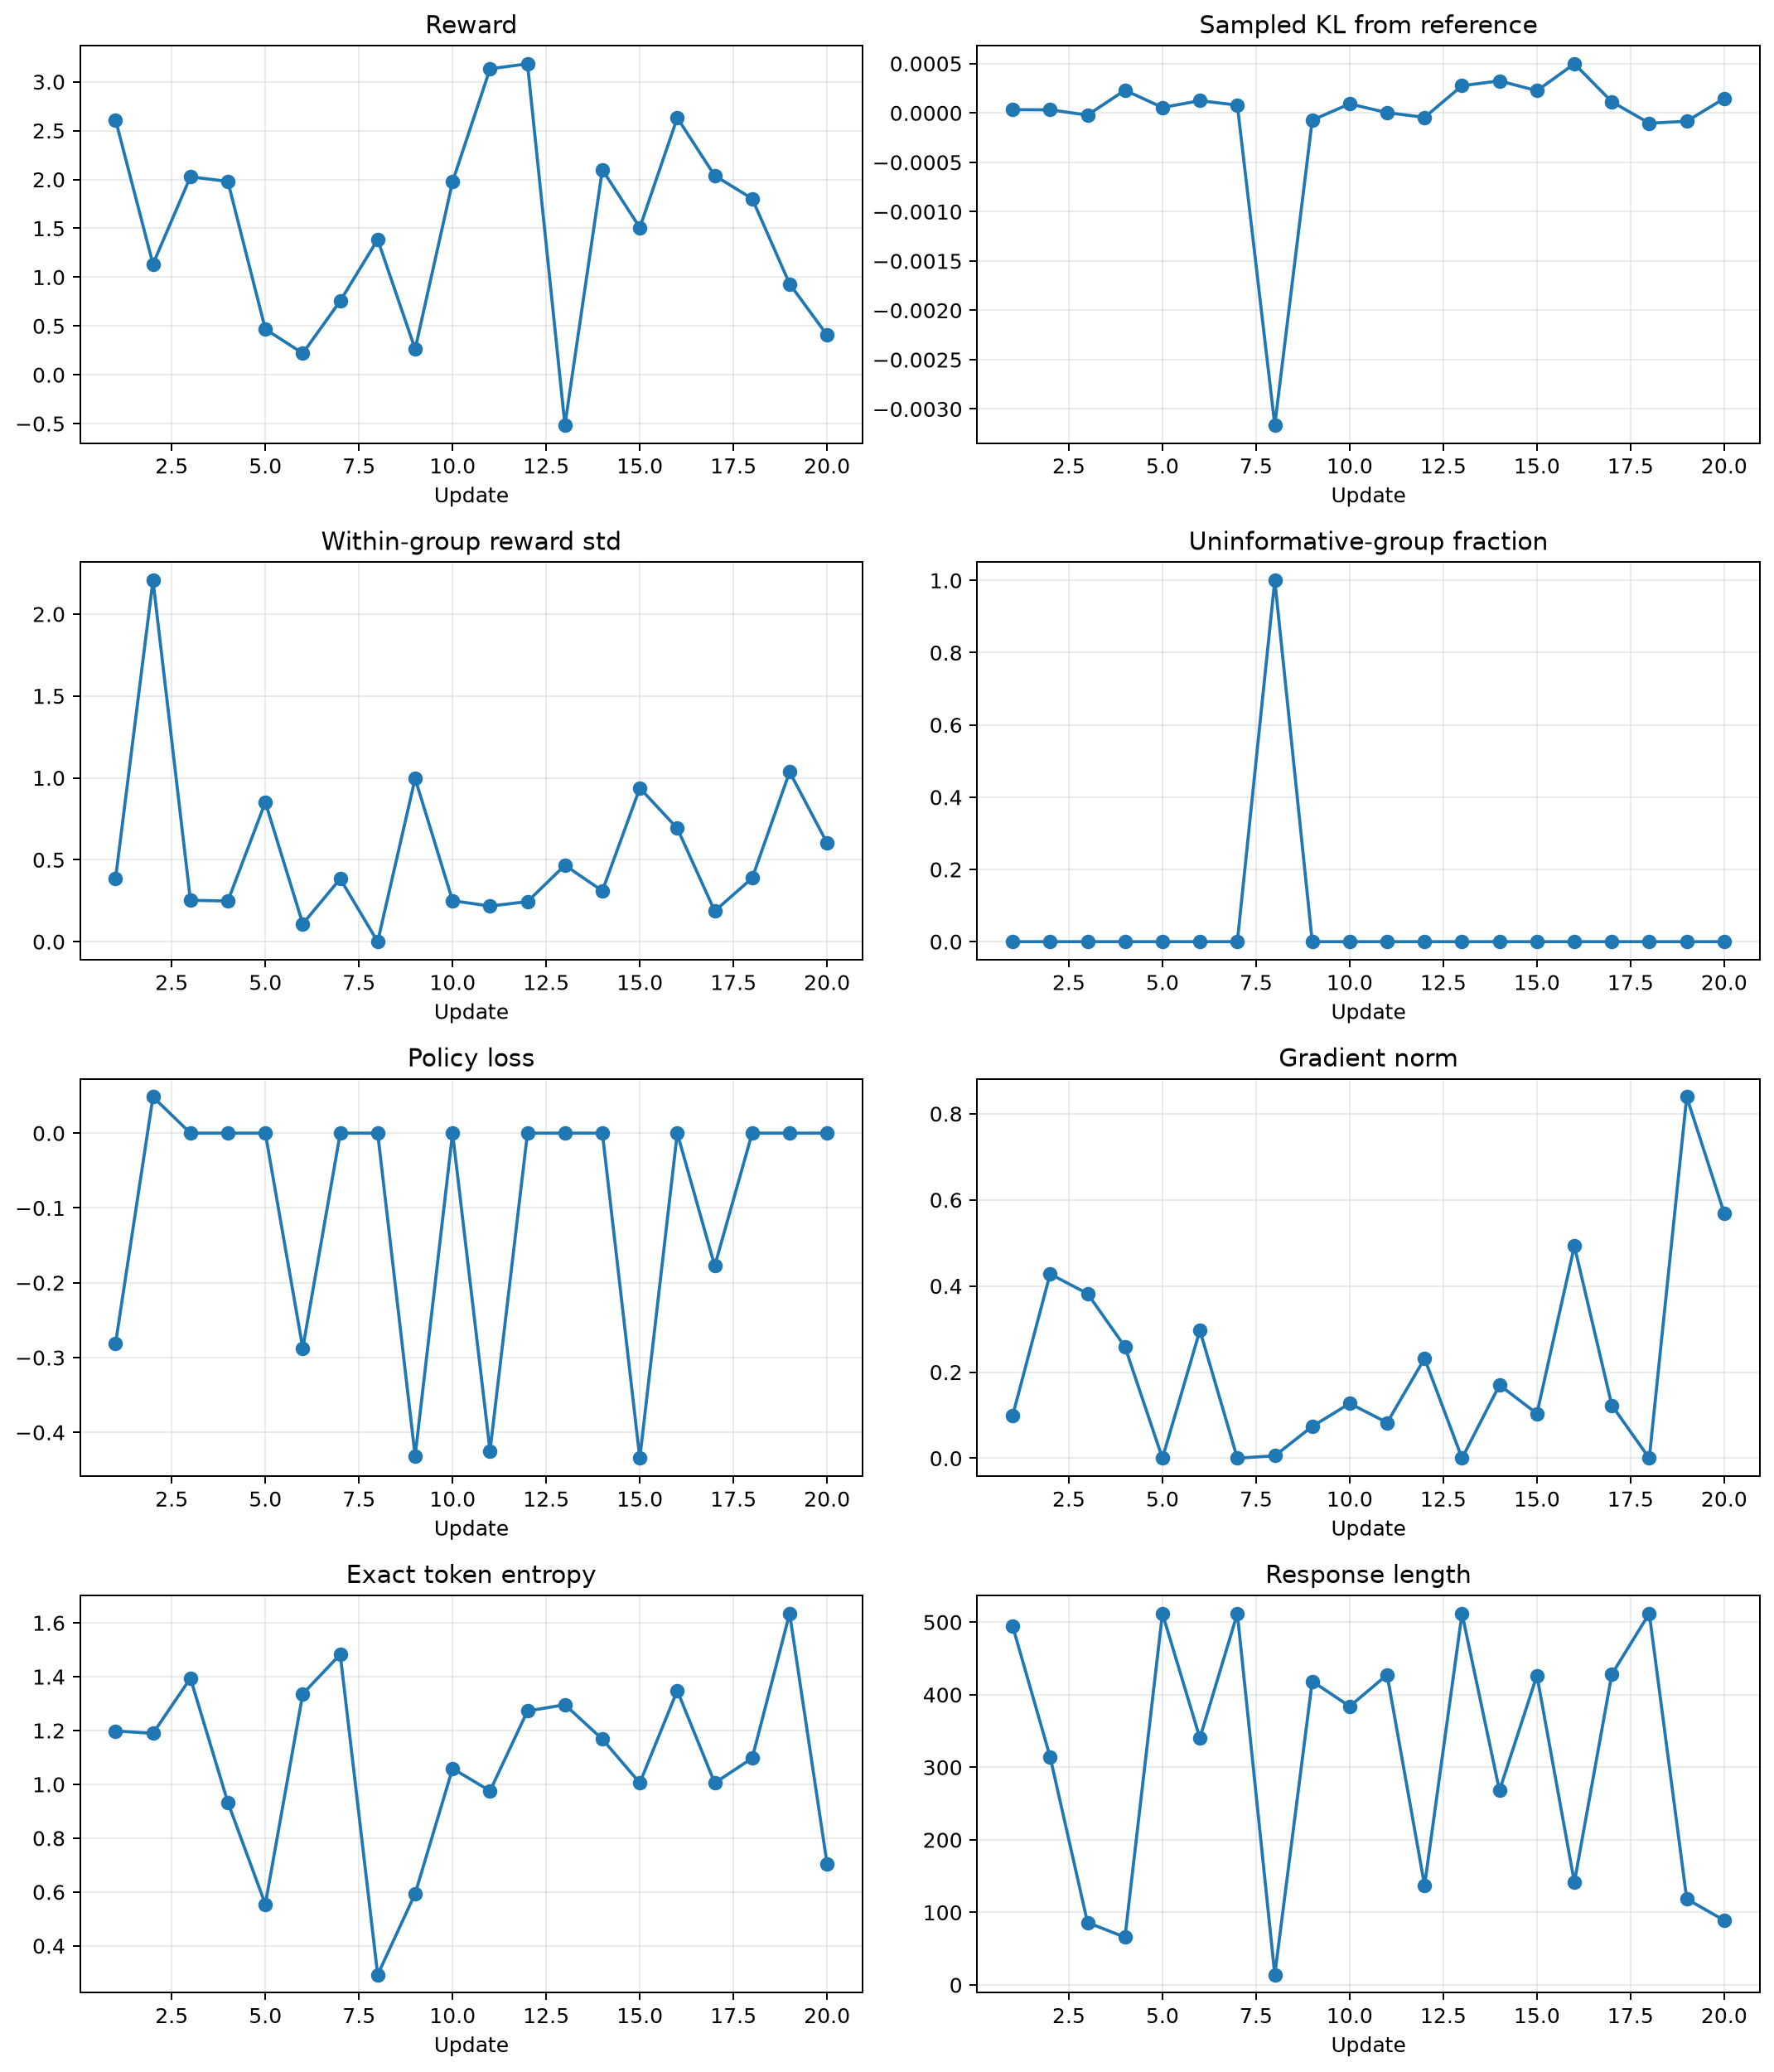

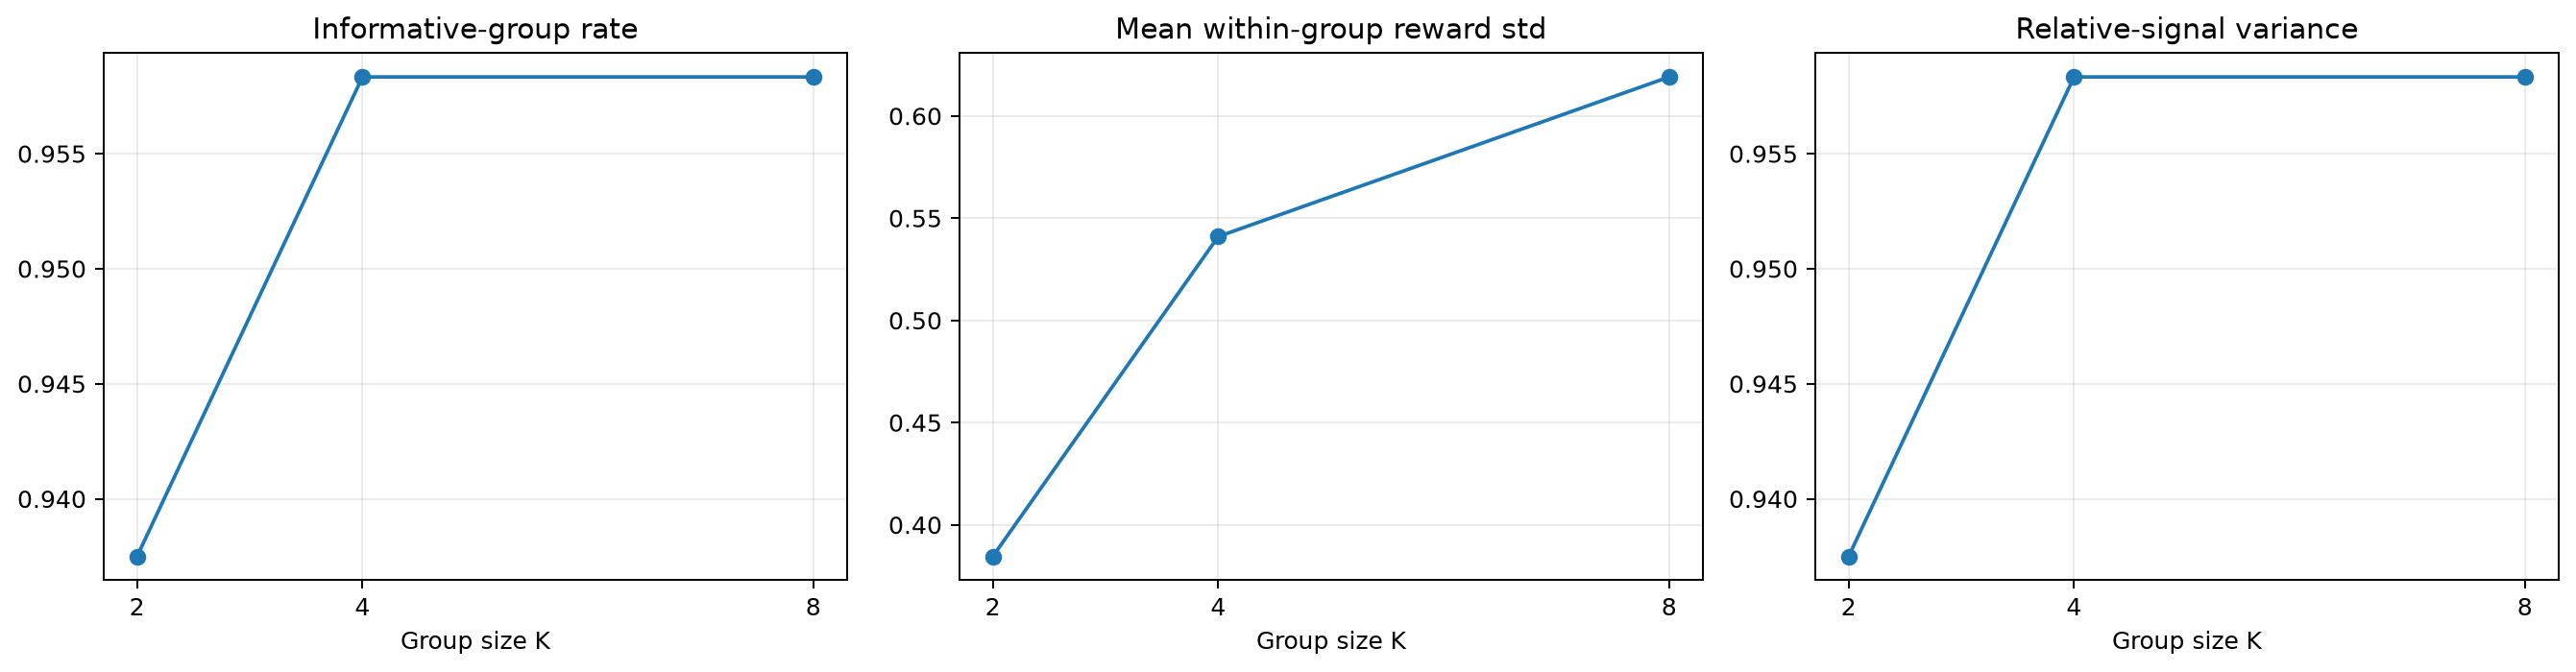

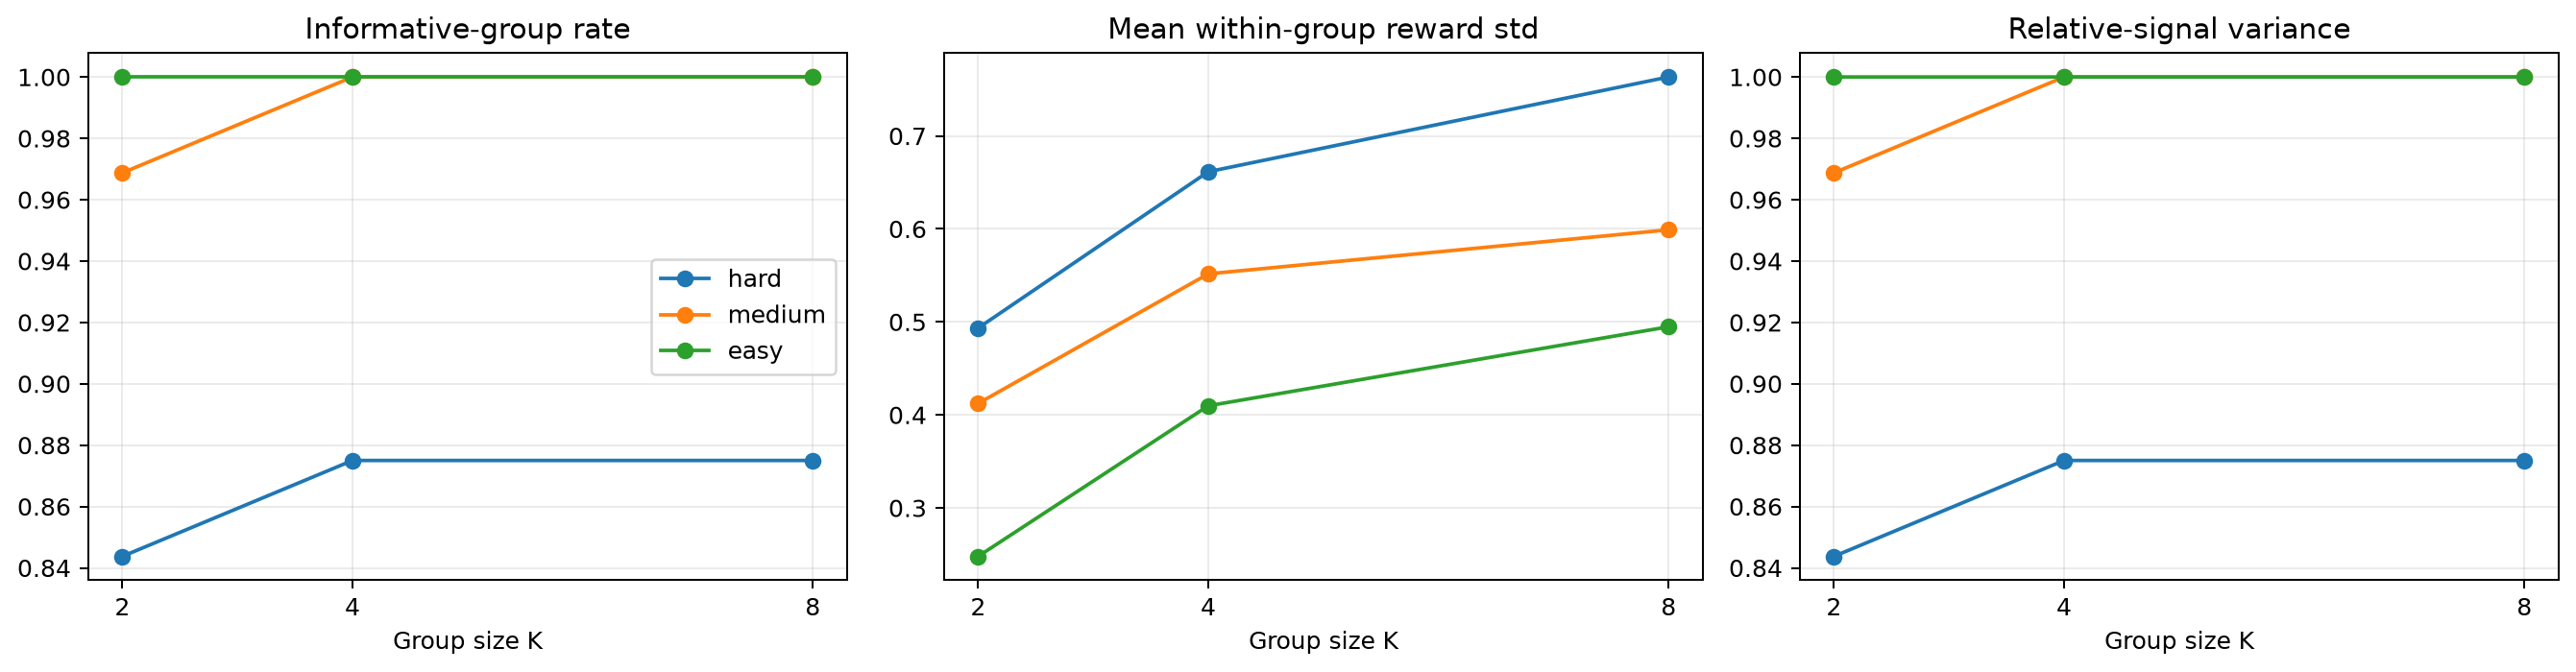

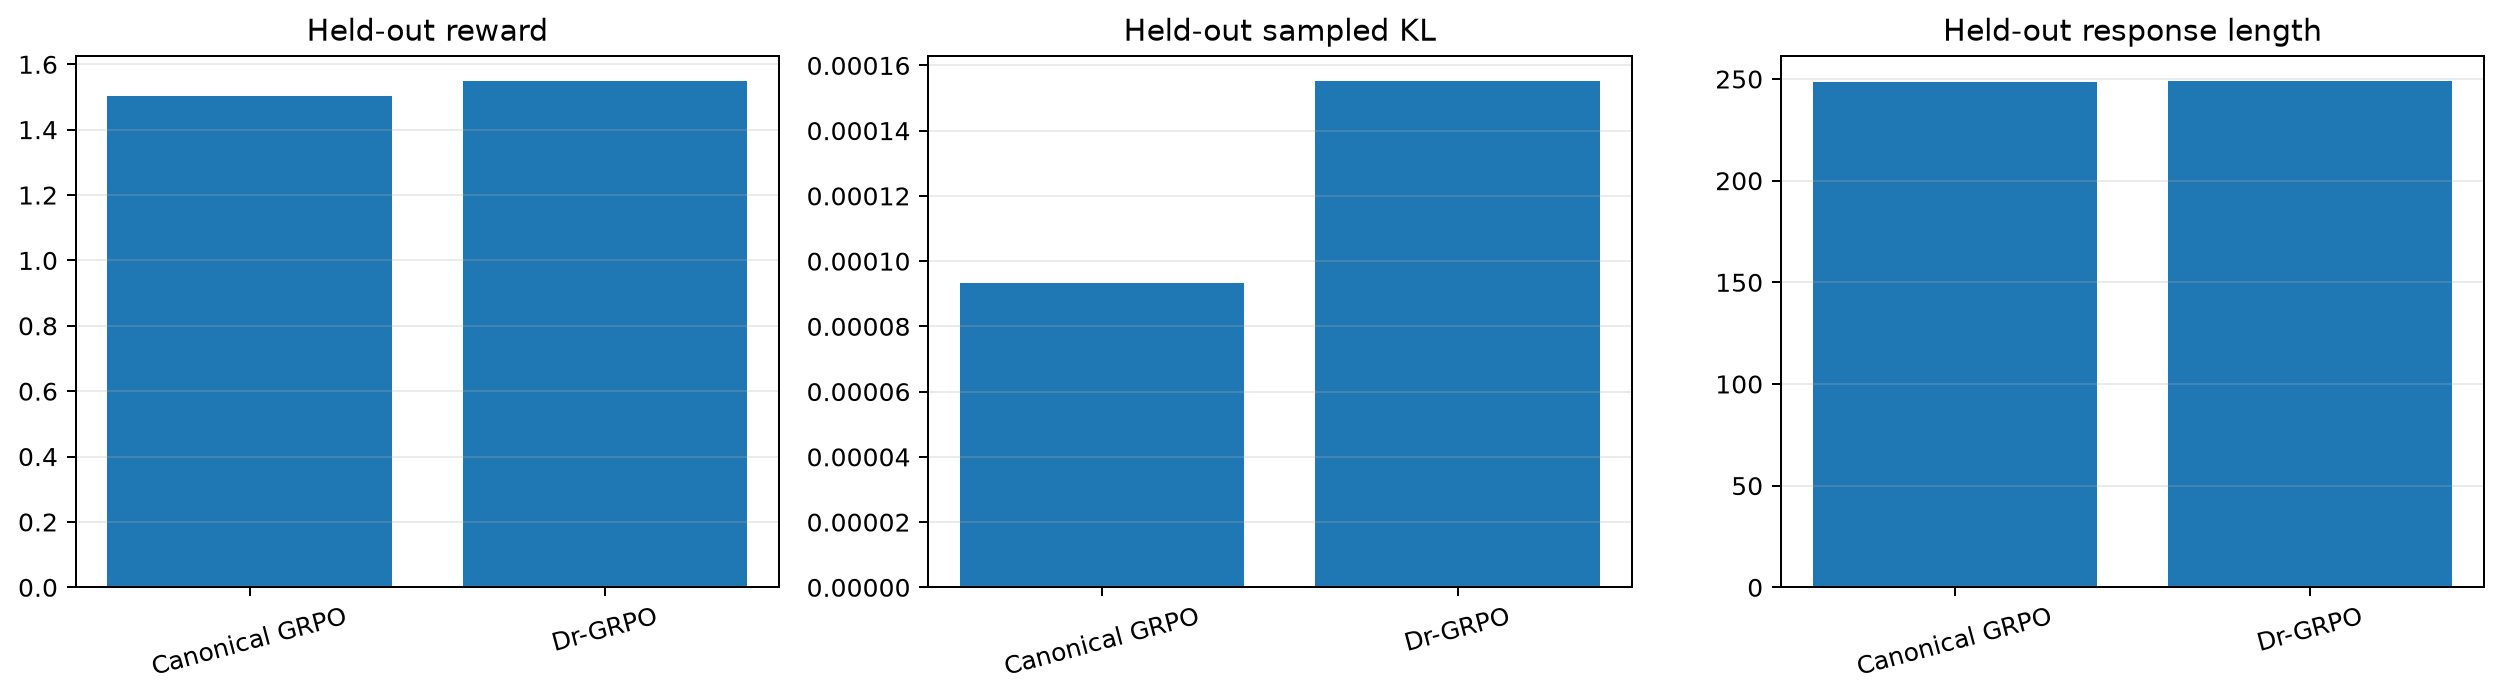

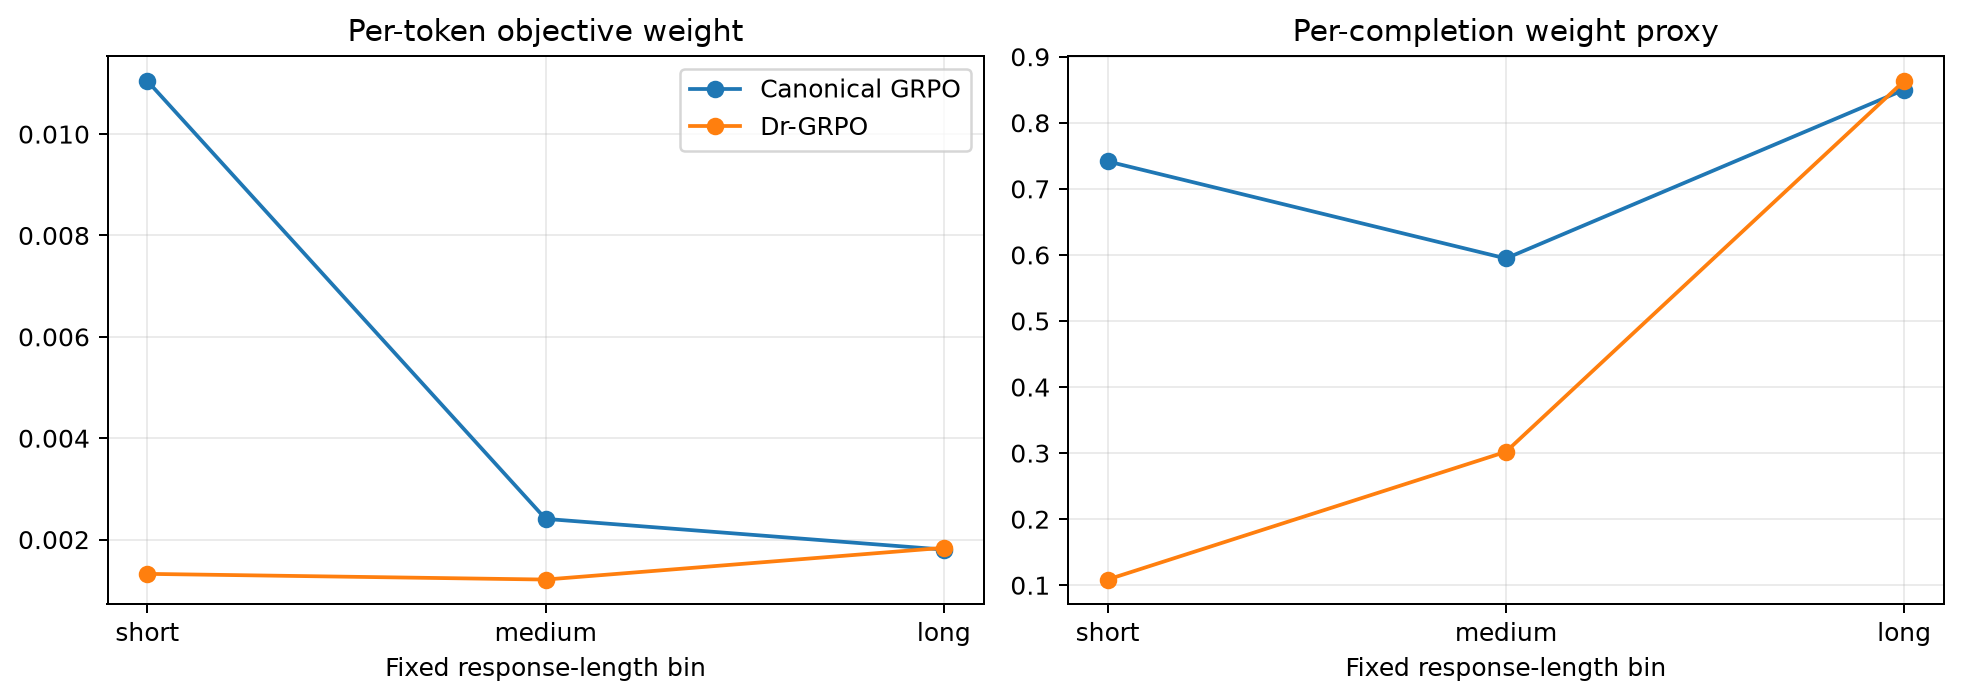

In [12]:
from task3_grpo.analysis.aggregate import build_available_evidence
from task3_grpo.analysis.plots import save_available_figures

results_root = repo_path(config['results_dir'])
standard_dir = results_root / 'standard'
group_dir = results_root / 'group_size'
normalization_root = results_root / 'normalization'
figures_dir = results_root / 'figures'
evidence = build_available_evidence(config)
save_available_figures(config)
if (standard_dir / 'stability_diagnostics.json').exists():
    from common.logging_utils import load_json
    display(pd.DataFrame([load_json(standard_dir / 'stability_diagnostics.json')]))
display(pd.read_csv(group_dir / 'summary.csv'))
display(pd.read_csv(group_dir / 'difficulty_summary.csv'))
if (normalization_root / 'summary.csv').exists():
    display(pd.read_csv(normalization_root / 'summary.csv'))
    display(pd.read_csv(normalization_root / 'length_conditioned_metrics.csv'))
for figure_name in [
    'standard_training.png',
    'group_size_overall.png',
    'group_size_by_difficulty.png',
    'normalization_heldout.png',
    'normalization_length_allocation.png',
]:
    figure_path = figures_dir / figure_name
    if figure_path.exists():
        display(Image(filename=str(figure_path)))

In [13]:
def inspect_run(run_name='standard'):
    if run_name == 'standard':
        directory = repo_path(config['results_dir']) / 'standard'
    else:
        directory = repo_path(config['results_dir']) / 'normalization' / run_name
    display(pd.DataFrame(read_jsonl(directory / 'train_metrics.jsonl')))
    if (directory / 'eval_metrics.json').exists():
        from common.logging_utils import load_json
        metrics = load_json(directory / 'eval_metrics.json')
        display(pd.DataFrame([metrics]).drop(columns=['evaluation_protocol', 'reward_scoring_protocol']))

try:
    import ipywidgets as widgets
    widgets.interact(
        inspect_run,
        run_name=widgets.Dropdown(
            options=['standard', 'norm_canonical', 'norm_dr_grpo'],
            description='Run:',
        ),
    )
except ImportError:
    print("ipywidgets is optional. Call inspect_run('standard') manually.")

ipywidgets is optional. Call inspect_run('standard') manually.


## Manual review

In [14]:
def show_standard_example(index=1):
    directory = repo_path(config['results_dir']) / 'standard'
    rows = read_jsonl(directory / 'qualitative_candidates.jsonl')
    row = rows[index]
    display(Markdown(
        f"**Reason:** {row['candidate_reason']}  \\n**Prompt:** {row['prompt']}  \\n"
        f"**Response:** {row['response']}  \\n**Reward:** {row['reward_model_score']:.4f}, "
        f"**KL:** {row['sampled_kl_token_mean']:.5f}, **Length:** {row['response_length']}"
    ))

def show_normalization_example(index=1):
    directory = repo_path(config['results_dir']) / 'normalization'
    rows = read_jsonl(directory / 'qualitative_comparisons.jsonl')
    row = rows[index]
    display(Markdown(
        f"**Prompt:** {row['prompt']}  \\n"
        f"**Canonical:** {row['canonical']['response']}  \\n"
        f"**Dr-GRPO:** {row['dr_grpo']['response']}"
    ))

print('Use show_standard_example(index) or show_normalization_example(index).')

Use show_standard_example(index) or show_normalization_example(index).
